**Give Me Some Credit: credit-risk data preparation**

**Setup**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})
BLUE, YELLOW, SKY = "#A9D6F5", "#FBE7A1", "#CFE8FA"

TARGET = "SeriousDlqin"
PAST_DUE = ["NumberOfTime30-59DaysPastDueNotWorse",
            "NumberOfTime60-89DaysPastDueNotWorse",
            "NumberOfTimes90DaysLate"]
NUM_COLS = ["age", "RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome",
            "NumberOfOpenCreditLinesAndLoans", "NumberRealEstateLoansOrLines",
            "NumberOfDependents"] + PAST_DUE

**Q1: Load data and inspect structure**

In [2]:
df = pd.read_csv("GiveMeSomeCredit.csv")
df["SEX"] = df["SEX"].map({"M": 0, "F": 1})
print("Shape:", df.shape)
df.head()

Shape: (149724, 14)


,SeriousDlqin,RevolvingUtilizationOfUnsecuredLines,age,SEX,EDUCATION,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,NumberOfDefault
0,1,0.878881,40,1,3,0,0.605616,12000.0,19,2,3,11,0.0,1
1,0,1.000000,34,1,1,3,2121.000000,0.0,9,0,2,9,2.0,0
2,0,0.470085,59,1,1,5,1.280078,15916.0,34,6,14,8,0.0,0
3,1,0.908082,26,0,3,3,1.444855,6500.0,22,1,4,8,0.0,2
4,1,1.000000,36,0,3,4,0.913676,2200.0,10,1,1,7,1.0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149724 entries, 0 to 149723
Data columns (total 14 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin                          149724 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  149724 non-null  float64
 2   age                                   149724 non-null  int64  
 3   SEX                                   149724 non-null  int64  
 4   EDUCATION                             149724 non-null  int64  
 5   NumberOfTime30-59DaysPastDueNotWorse  149724 non-null  int64  
 6   DebtRatio                             149724 non-null  float64
 7   MonthlyIncome                         120117 non-null  float64
 8   NumberOfOpenCreditLinesAndLoans       149724 non-null  int64  
 9   NumberOfTimes90DaysLate               149724 non-null  int64  
 10  NumberRealEstateLoansOrLines          149724 non-null  int64  
 11  NumberOfTim

**Q2: Target distribution**

In [4]:
target_summary = pd.DataFrame({
    "Count": df[TARGET].value_counts(),
    "Percent": df[TARGET].value_counts(normalize=True).mul(100).round(2),
})
target_summary

,Count,Percent
SeriousDlqin,,
0,139845,93.4
1,9879,6.6


**Q3 (a): Duplicate rows**

In [5]:
print("Duplicated rows:", df.duplicated().sum())
df[df.duplicated(keep=False)].describe().T[["min", "max"]]

Duplicated rows: 142


,min,max
SeriousDlqin,0.0,0.000000
RevolvingUtilizationOfUnsecuredLines,0.0,1.000000
age,21.0,96.000000
SEX,0.0,1.000000
EDUCATION,1.0,3.000000
NumberOfTime30-59DaysPastDueNotWorse,0.0,0.000000
DebtRatio,0.0,0.633374
MonthlyIncome,0.0,929.000000
NumberOfOpenCreditLinesAndLoans,0.0,8.000000
NumberOfTimes90DaysLate,0.0,1.000000


Duplicates are kept: they are only 0.09% of rows, and without a customer ID identical rows may be different people.

**Q3 (b): Impossible values**

In [6]:
checks = {
    "age < 18": (df["age"] < 18).sum(),
    "age > 100": (df["age"] > 100).sum(),
    "MonthlyIncome < 0": (df["MonthlyIncome"] < 0).sum(),
    "NumberRealEstateLoansOrLines < 0": (df["NumberRealEstateLoansOrLines"] < 0).sum(),
}
print(pd.Series(checks))
df = df[df["age"].between(18, 100)].copy()
print("Rows after filter:", len(df))

age < 18                             1
age > 100                           13
MonthlyIncome < 0                    0
NumberRealEstateLoansOrLines < 0     0
dtype: int64
Rows after filter: 149710


**Q4: Target leakage**

In [7]:
corr_target = df.corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print(corr_target.round(3))
print()
print(pd.crosstab(df["NumberOfDefault"], df[TARGET]))

NumberOfDefault                         0.922
NumberOfTimes90DaysLate                 0.315
NumberOfTime30-59DaysPastDueNotWorse    0.275
NumberOfTime60-89DaysPastDueNotWorse    0.268
NumberOfDependents                      0.047
EDUCATION                               0.002
RevolvingUtilizationOfUnsecuredLines   -0.002
SEX                                    -0.003
NumberRealEstateLoansOrLines           -0.004
DebtRatio                              -0.009
MonthlyIncome                          -0.023
NumberOfOpenCreditLinesAndLoans        -0.024
age                                    -0.113
Name: SeriousDlqin, dtype: float64

SeriousDlqin          0     1
NumberOfDefault              
0                139832     0
1                     0  3260
2                     0  3257
3                     0  3361


`NumberOfDefault` is 0 exactly when the target is 0, so it encodes the label itself. It is dropped.

In [8]:
df = df.drop(columns=["NumberOfDefault"])
print("Columns left:", df.shape[1])

Columns left: 13


**Q5: Stratified train/test split**

In [9]:
X = df.drop(columns=[TARGET])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

train_df = X_train.assign(**{TARGET: y_train})
test_df = X_test.assign(**{TARGET: y_test})

print("Train:", train_df.shape, "| Test:", test_df.shape)
pd.DataFrame({
    "Overall %": y.mean() * 100,
    "Train %": y_train.mean() * 100,
    "Test %": y_test.mean() * 100,
}, index=["Bad rate"]).round(2)

Train: (104797, 13) | Test: (44913, 13)


,Overall %,Train %,Test %
Bad rate,6.6,6.6,6.6


**Q6 (a): Missing values**

In [10]:
def missing_report(d):
    return pd.DataFrame({"Count": d.isna().sum(),
                         "Percent": d.isna().mean().mul(100).round(2)}
                        ).query("Count > 0")

print("Train"); print(missing_report(train_df))
print("\nTest"); print(missing_report(test_df))

Train
                    Count  Percent
MonthlyIncome       20723    19.77
NumberOfDependents   2767     2.64

Test
                    Count  Percent
MonthlyIncome        8877    19.76
NumberOfDependents   1123     2.50


**Q6 (b): Is missingness informative?**

In [11]:
for col in ["MonthlyIncome", "NumberOfDependents"]:
    rate = train_df.groupby(train_df[col].isna())[TARGET].mean().mul(100).round(2)
    rate.index = ["Observed", "Missing"]
    print(col, "bad rate %:", rate.to_dict())

MonthlyIncome bad rate %: {'Observed': 6.88, 'Missing': 5.47}
NumberOfDependents bad rate %: {'Observed': 6.66, 'Missing': 4.23}


**Q6 (c): Median imputation (train statistics only)**

In [12]:
for d in (train_df, test_df):
    d["MonthlyIncome_missing"] = d["MonthlyIncome"].isna().astype(int)

medians = train_df[["MonthlyIncome", "NumberOfDependents"]].median()
print(medians)

for d in (train_df, test_df):
    d.fillna(medians, inplace=True)
print("Remaining NaN:", train_df.isna().sum().sum() + test_df.isna().sum().sum())

MonthlyIncome         5416.0
NumberOfDependents       0.0
dtype: float64
Remaining NaN: 0


**Q7 (a): Outliers (IQR rule)**

In [13]:
rows = []
flags = pd.DataFrame(index=train_df.index)
for col in NUM_COLS:
    q1, q3 = train_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flags[col] = (train_df[col] < lo) | (train_df[col] > hi)
    rows.append({"Feature": col, "Q1": q1, "Q3": q3, "Lower": lo, "Upper": hi,
                 "Outliers": flags[col].sum(),
                 "Outlier %": round(flags[col].mean() * 100, 2),
                 "Max": train_df[col].max()})
outlier_report = pd.DataFrame(rows).sort_values("Outlier %", ascending=False)
outlier_report.round(2)

,Feature,Q1,Q3,Lower,Upper,Outliers,Outlier %,Max
2,DebtRatio,0.18,0.86,-0.86,1.90,21865,20.86,220516.0
7,NumberOfTime30-59DaysPastDueNotWorse,0.00,0.00,0.00,0.00,16510,15.75,13.0
6,NumberOfDependents,0.00,1.00,-1.50,2.50,9337,8.91,10.0
3,MonthlyIncome,3923.00,7420.00,-1322.50,12665.50,6367,6.08,1794060.0
9,NumberOfTimes90DaysLate,0.00,0.00,0.00,0.00,5652,5.39,15.0
8,NumberOfTime60-89DaysPastDueNotWorse,0.00,0.00,0.00,0.00,5134,4.90,9.0
4,NumberOfOpenCreditLinesAndLoans,5.00,11.00,-4.00,20.00,2752,2.63,57.0
1,RevolvingUtilizationOfUnsecuredLines,0.03,0.56,-0.76,1.34,542,0.52,22198.0
5,NumberRealEstateLoansOrLines,0.00,2.00,-3.00,5.00,543,0.52,32.0
0,age,41.00,63.00,8.00,96.00,21,0.02,99.0


**Q7 (b): Bad rate inside vs outside the fences**

In [14]:
cmp = pd.DataFrame({
    col: {"Bad rate % (outlier)": train_df.loc[flags[col], TARGET].mean() * 100,
          "Bad rate % (normal)": train_df.loc[~flags[col], TARGET].mean() * 100}
    for col in NUM_COLS}).T.round(2)
cmp.sort_values("Bad rate % (outlier)", ascending=False)

,Bad rate % (outlier),Bad rate % (normal)
NumberOfTimes90DaysLate,41.91,4.59
NumberOfTime60-89DaysPastDueNotWorse,35.90,5.09
RevolvingUtilizationOfUnsecuredLines,29.34,6.48
NumberOfTime30-59DaysPastDueNotWorse,20.73,3.96
NumberRealEstateLoansOrLines,16.02,6.55
NumberOfDependents,9.23,6.34
NumberOfOpenCreditLinesAndLoans,7.01,6.59
DebtRatio,5.66,6.85
age,4.76,6.60
MonthlyIncome,4.55,6.73


Outliers are flagged, not removed: the heavy tails in the past-due counts carry most of the default signal.

**Q8 (a): Feature means by target**

In [15]:
pd.concat({"Mean": train_df.groupby(TARGET)[NUM_COLS].mean().T,
           "Median": train_df.groupby(TARGET)[NUM_COLS].median().T},
          axis=1).round(3)

Mean              Median          
SeriousDlqin                                 0         1         0         1
age                                     52.785    46.061    52.000    46.000
RevolvingUtilizationOfUnsecuredLines     6.186     6.002     0.133     0.831
DebtRatio                              352.223   305.816     0.363     0.430
MonthlyIncome                         6447.126  5644.865  5416.000  5281.000
NumberOfOpenCreditLinesAndLoans          8.502     7.947     8.000     7.000
NumberRealEstateLoansOrLines             1.021     0.994     1.000     1.000
NumberOfDependents                       0.724     0.941     0.000     0.000
NumberOfTime30-59DaysPastDueNotWorse     0.193     0.977     0.000     0.000
NumberOfTime60-89DaysPastDueNotWorse     0.041     0.402     0.000     0.000
NumberOfTimes90DaysLate                  0.050     0.672     0.000     0.000

**Q8 (b): Distributions by target**

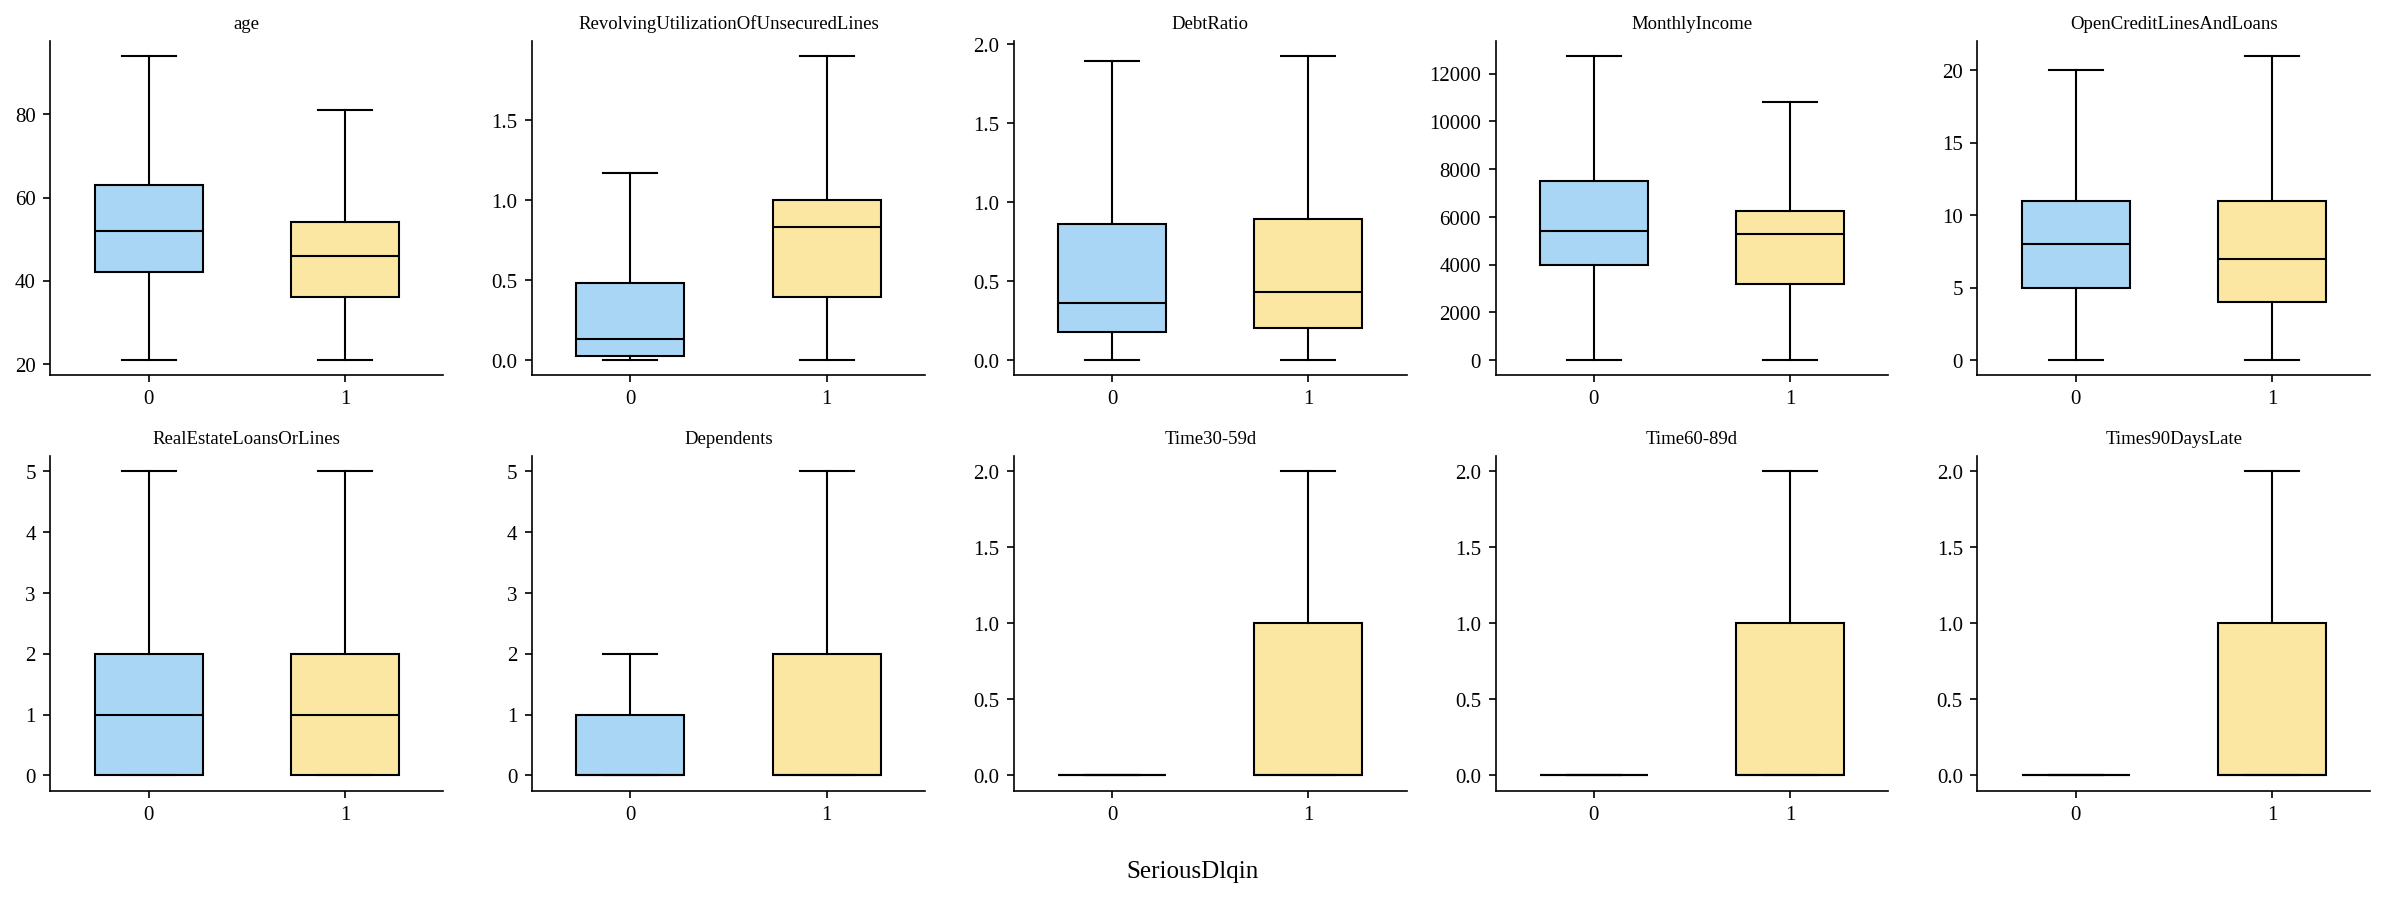

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), NUM_COLS):
    data = [train_df.loc[train_df[TARGET] == k, col] for k in (0, 1)]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.55,
                    medianprops={"color": "black"})
    for patch, c in zip(bp["boxes"], (BLUE, YELLOW)):
        patch.set_facecolor(c)
    ax.set_xticklabels(["0", "1"])
    ax.set_title(col.replace("NumberOf", "").replace("Number", "").replace("DaysPastDueNotWorse", "d"), fontsize=9)
fig.supxlabel("SeriousDlqin")
plt.tight_layout()
plt.show()

**Q9: Categorical features (train only)**

In [17]:
def bad_rate(d, col):
    out = d.groupby(col)[TARGET].agg(Customers="size", Bad_Rate="mean")
    out["Bad_Rate"] = (out["Bad_Rate"] * 100).round(2)
    return out

print(bad_rate(train_df, "SEX"))
print()
print(bad_rate(train_df, "EDUCATION"))

     Customers  Bad_Rate
SEX                     
0        41808      6.58
1        62989      6.61

           Customers  Bad_Rate
EDUCATION                     
1              26275      6.62
2              36528      6.71
3              36724      6.45
4               5270      6.72


**Q10 (a): Past-due features**

In [18]:
def add_features(d):
    d["TotalPastDue"] = d[PAST_DUE].sum(axis=1)
    d["Has90DaysLate"] = (d["NumberOfTimes90DaysLate"] > 0).astype(int)
    d["WorstDelayStatus"] = np.select(
        [d["NumberOfTimes90DaysLate"] > 0,
         d["NumberOfTime60-89DaysPastDueNotWorse"] > 0,
         d["NumberOfTime30-59DaysPastDueNotWorse"] > 0],
        [3, 2, 1], default=0)
    return d

train_df = add_features(train_df)
test_df = add_features(test_df)
NEW = ["TotalPastDue", "Has90DaysLate", "WorstDelayStatus"]
train_df[PAST_DUE + NEW].head()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate,TotalPastDue,Has90DaysLate,WorstDelayStatus
134668,0,0,0,0,0,0
119703,0,0,0,0,0,0
37115,0,0,0,0,0,0
141624,0,0,0,0,0,0
139483,0,0,0,0,0,0


**Q10 (b): Bad rate by new features**

In [19]:
print(bad_rate(train_df, "Has90DaysLate"))
print()
print(bad_rate(train_df, "WorstDelayStatus"))
print()
train_df.groupby(TARGET)[NEW].mean().T.round(3)

               Customers  Bad_Rate
Has90DaysLate                     
0                  99145      4.59
1                   5652     41.91

                  Customers  Bad_Rate
WorstDelayStatus                     
0                     83858      2.66
1                     11931     12.12
2                      3356     25.80
3                      5652     41.91



SeriousDlqin,0,1
TotalPastDue,0.284,2.052
Has90DaysLate,0.034,0.343
WorstDelayStatus,0.259,1.487


**Q11 (a): Age and debt-ratio bins**

In [20]:
age_bins = [0, 29, 39, 49, 59, 69, np.inf]
age_labels = ["<30", "30-39", "40-49", "50-59", "60-69", "70+"]
train_df["AgeGroup"] = pd.cut(train_df["age"], age_bins, labels=age_labels)
test_df["AgeGroup"] = pd.cut(test_df["age"], age_bins, labels=age_labels)

_, edges = pd.qcut(train_df["DebtRatio"], q=5, retbins=True, duplicates="drop")
edges[0], edges[-1] = -np.inf, np.inf
train_df["DebtRatioGroup"] = pd.cut(train_df["DebtRatio"], edges)
test_df["DebtRatioGroup"] = pd.cut(test_df["DebtRatio"], edges)

print(bad_rate(train_df, "AgeGroup"))
print()
print(bad_rate(train_df, "DebtRatioGroup"))

          Customers  Bad_Rate
AgeGroup                     
<30            6103     11.17
30-39         16157      9.96
40-49         23946      8.32
50-59         24736      6.44
60-69         20305      3.56
70+           13550      2.33

                Customers  Bad_Rate
DebtRatioGroup                     
(-inf, 0.135]       20961      5.68
(0.135, 0.288]      20958      5.76
(0.288, 0.467]      20959      6.25
(0.467, 4.0]        21052      9.78
(4.0, inf]          20867      5.51


In [21]:
train_df.groupby("DebtRatioGroup", observed=False)["MonthlyIncome_missing"].mean().mul(100).round(1)

,MonthlyIncome_missing
DebtRatioGroup,
"(-inf, 0.135]",5.2
"(0.135, 0.288]",0.0
"(0.288, 0.467]",0.0
"(0.467, 4.0]",2.3
"(4.0, inf]",91.8


The top debt-ratio bin is mostly customers with missing income, so its ratio is not comparable with the other bins.

**Q11 (b): Weight of evidence and information value**

In [22]:
def woe_iv(d, col):
    t = d.groupby(col, observed=False)[TARGET].agg(Total="size", Bad="sum")
    t["Good"] = t["Total"] - t["Bad"]
    t["Bad_Dist"] = t["Bad"] / t["Bad"].sum()
    t["Good_Dist"] = t["Good"] / t["Good"].sum()
    t["WOE"] = np.log(t["Good_Dist"] / t["Bad_Dist"])
    t["IV"] = (t["Good_Dist"] - t["Bad_Dist"]) * t["WOE"]
    return t

woe_age = woe_iv(train_df, "AgeGroup")
print("IV (age) =", round(woe_age["IV"].sum(), 4))
woe_age.round(4)

IV (age) = 0.2379


,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
AgeGroup,,,,,,,
<30,6103,682,5421,0.0986,0.0554,-0.5771,0.0250
30-39,16157,1610,14547,0.2328,0.1486,-0.4489,0.0378
40-49,23946,1992,21954,0.2881,0.2243,-0.2503,0.0160
50-59,24736,1592,23144,0.2302,0.2364,0.0267,0.0002
60-69,20305,723,19582,0.1046,0.2001,0.6489,0.0620
70+,13550,316,13234,0.0457,0.1352,1.0847,0.0971


In [23]:
woe_debt = woe_iv(train_df, "DebtRatioGroup")
print("IV (debt ratio) =", round(woe_debt["IV"].sum(), 4))
woe_debt.round(4)

IV (debt ratio) = 0.0606


,Total,Bad,Good,Bad_Dist,Good_Dist,WOE,IV
DebtRatioGroup,,,,,,,
"(-inf, 0.135]",20961,1190,19771,0.1721,0.2020,0.1602,0.0048
"(0.135, 0.288]",20958,1207,19751,0.1745,0.2018,0.1450,0.0039
"(0.288, 0.467]",20959,1310,19649,0.1894,0.2007,0.0579,0.0007
"(0.467, 4.0]",21052,2059,18993,0.2978,0.1940,-0.4282,0.0444
"(4.0, inf]",20867,1149,19718,0.1662,0.2014,0.1926,0.0068


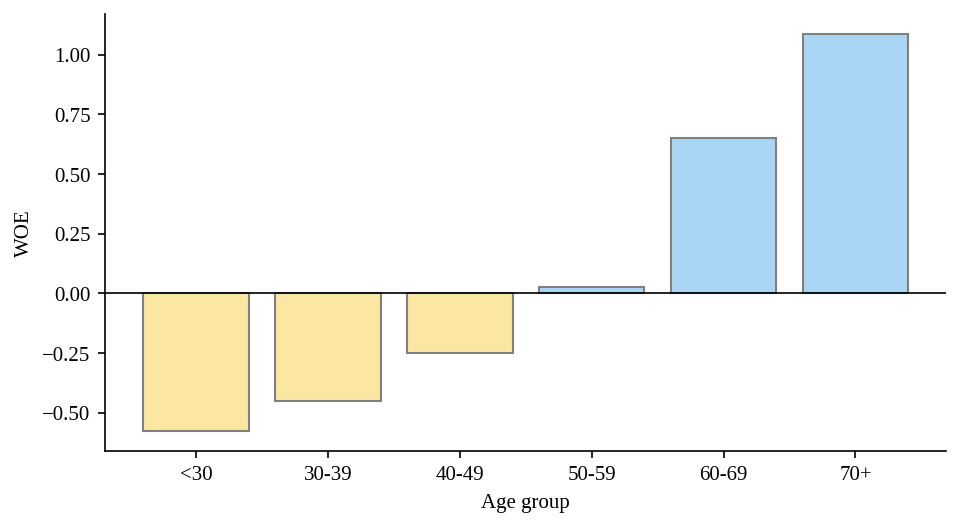

In [24]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.bar(age_labels, woe_age["WOE"], color=[YELLOW if w < 0 else BLUE for w in woe_age["WOE"]],
       edgecolor="grey")
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Age group")
ax.set_ylabel("WOE")
plt.tight_layout()
plt.show()

**Q12 (a): Feature redundancy**

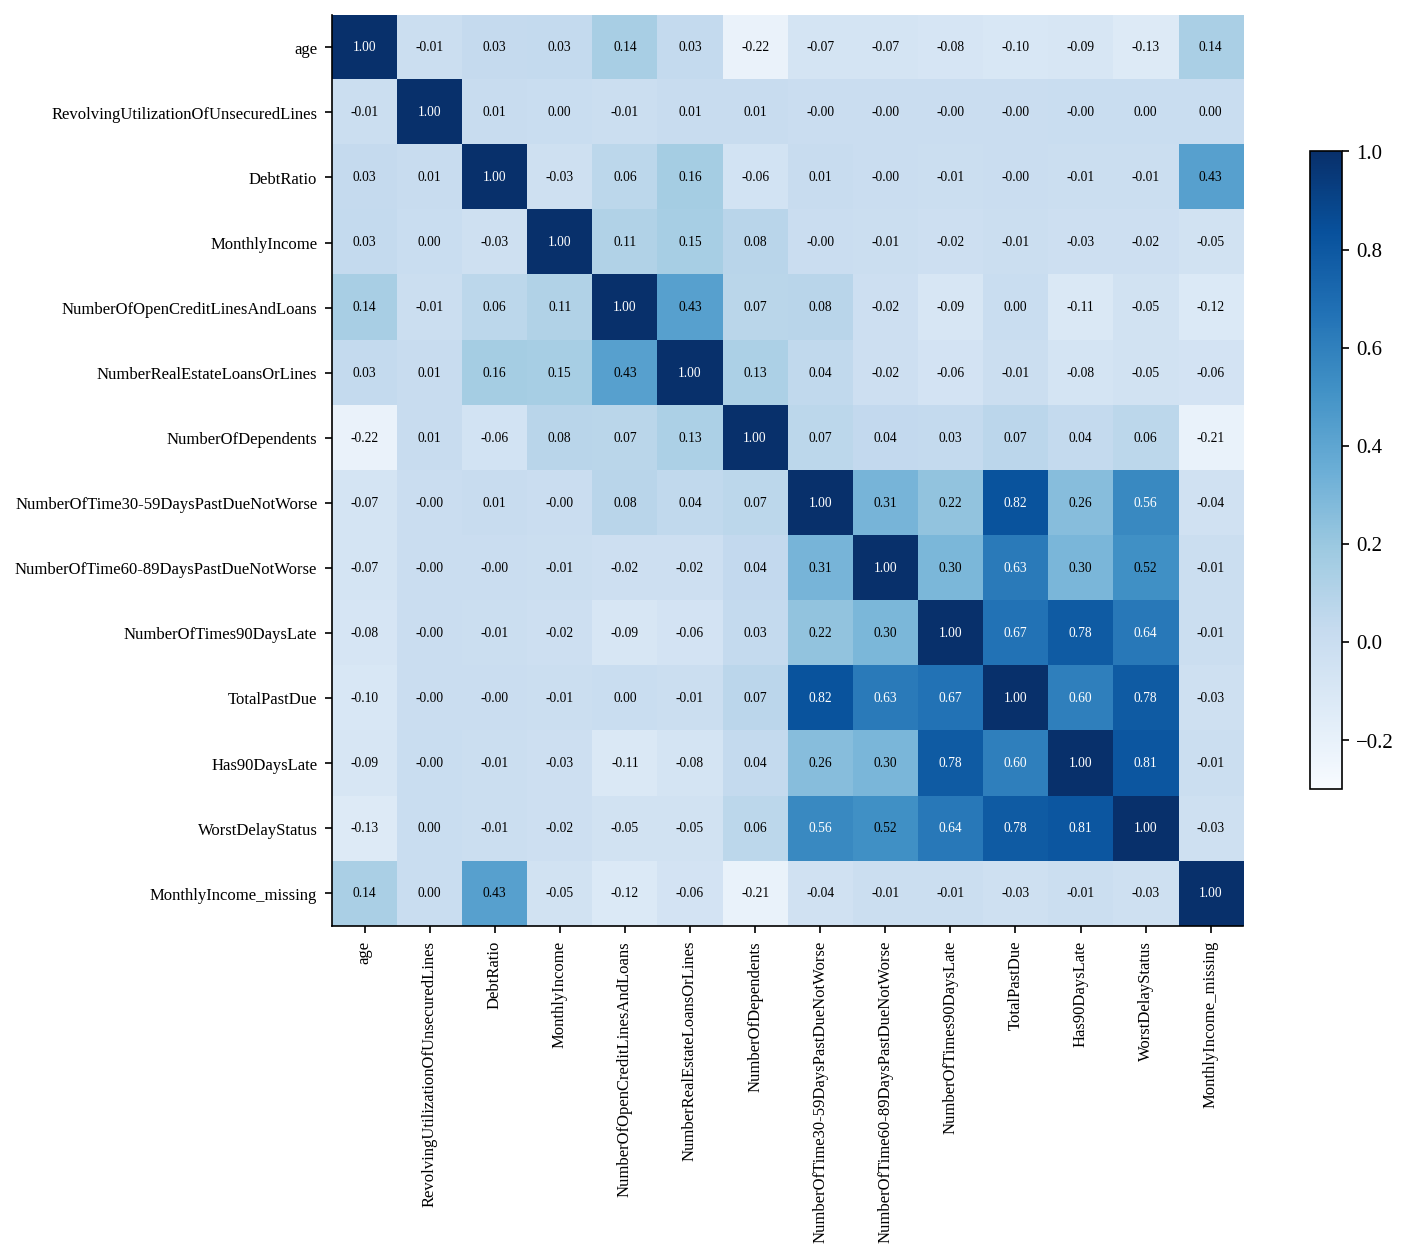

In [25]:
MODEL_COLS = NUM_COLS + NEW + ["MonthlyIncome_missing"]
corr = train_df[MODEL_COLS].corr()

fig, ax = plt.subplots(figsize=(11, 8.5))
im = ax.imshow(corr, cmap="Blues", vmin=-0.3, vmax=1)
ax.set_xticks(range(len(MODEL_COLS)), MODEL_COLS, rotation=90, fontsize=8)
ax.set_yticks(range(len(MODEL_COLS)), MODEL_COLS, fontsize=8)
for i in range(len(MODEL_COLS)):
    for j in range(len(MODEL_COLS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if corr.iloc[i, j] > 0.55 else "black")
fig.colorbar(im, shrink=0.7)
plt.tight_layout()
plt.show()

In [26]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3)

0
NumberOfTime30-59DaysPastDueNotWorse TotalPastDue      0.822
Has90DaysLate                        WorstDelayStatus  0.812
TotalPastDue                         WorstDelayStatus  0.785
NumberOfTimes90DaysLate              Has90DaysLate     0.783
                                     TotalPastDue      0.670
                                     WorstDelayStatus  0.636
NumberOfTime60-89DaysPastDueNotWorse TotalPastDue      0.626
TotalPastDue                         Has90DaysLate     0.599
NumberOfTime30-59DaysPastDueNotWorse WorstDelayStatus  0.555
NumberOfTime60-89DaysPastDueNotWorse WorstDelayStatus  0.518

**Q12 (b): Mutual information with the target**

TotalPastDue                            0.0492
WorstDelayStatus                        0.0478
RevolvingUtilizationOfUnsecuredLines    0.0370
NumberOfTimes90DaysLate                 0.0317
Has90DaysLate                           0.0304
NumberOfTime30-59DaysPastDueNotWorse    0.0259
NumberOfTime60-89DaysPastDueNotWorse    0.0208
age                                     0.0075
DebtRatio                               0.0042
MonthlyIncome                           0.0037
NumberOfOpenCreditLinesAndLoans         0.0032
NumberRealEstateLoansOrLines            0.0019
NumberOfDependents                      0.0012
MonthlyIncome_missing                   0.0003
EDUCATION                               0.0000
SEX                                     0.0000
dtype: float64


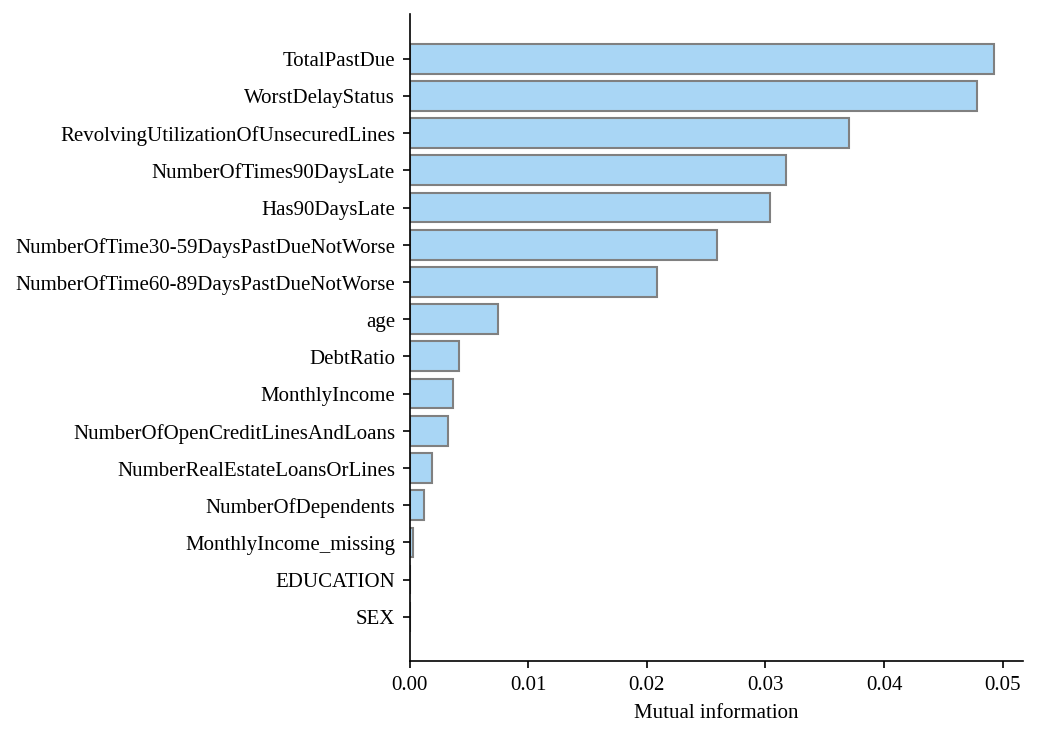

In [27]:
mi_X = train_df[MODEL_COLS + ["SEX", "EDUCATION"]]
discrete = [c in PAST_DUE + NEW + ["MonthlyIncome_missing", "SEX", "EDUCATION",
            "NumberOfDependents", "NumberOfOpenCreditLinesAndLoans",
            "NumberRealEstateLoansOrLines"] for c in mi_X.columns]

mi = mutual_info_classif(mi_X, train_df[TARGET], discrete_features=discrete, random_state=42)
mi_scores = pd.Series(mi, index=mi_X.columns).sort_values()
print(mi_scores.sort_values(ascending=False).round(4))

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(mi_scores.index, mi_scores.values, color=BLUE, edgecolor="grey")
ax.set_xlabel("Mutual information")
plt.tight_layout()
plt.show()

**Q13: Train vs test consistency**

In [28]:
check = pd.DataFrame({
    "Train mean": train_df[MODEL_COLS + ["SEX", "EDUCATION"]].mean(),
    "Test mean": test_df[MODEL_COLS + ["SEX", "EDUCATION"]].mean(),
})
check["Gap %"] = ((check["Test mean"] / check["Train mean"] - 1) * 100).round(2)
check.round(3)

,Train mean,Test mean,Gap %
age,52.342,52.281,-0.12
RevolvingUtilizationOfUnsecuredLines,6.174,4.660,-24.51
DebtRatio,349.161,342.658,-1.86
MonthlyIncome,6394.189,6434.311,0.63
NumberOfOpenCreditLinesAndLoans,8.466,8.472,0.08
NumberRealEstateLoansOrLines,1.019,1.021,0.11
NumberOfDependents,0.739,0.737,-0.28
NumberOfTime30-59DaysPastDueNotWorse,0.245,0.248,1.49
NumberOfTime60-89DaysPastDueNotWorse,0.065,0.064,-0.87
NumberOfTimes90DaysLate,0.091,0.090,-1.32


In [29]:
pd.concat({"Train": train_df.groupby(TARGET)[NEW].mean().T,
           "Test": test_df.groupby(TARGET)[NEW].mean().T}, axis=1).round(3)

Train          Test       
SeriousDlqin          0      1      0      1
TotalPastDue      0.284  2.052  0.291  1.977
Has90DaysLate     0.034  0.343  0.035  0.323
WorstDelayStatus  0.259  1.487  0.268  1.420